<a href="https://colab.research.google.com/github/ireniusliqfenermaward-maker/DATA_SCIENCE/blob/main/UTS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Library berhasil diimport! ---

--- 5 Baris Pertama Dataset Iris ---


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



--- Data Preparation & Normalisasi Selesai ---


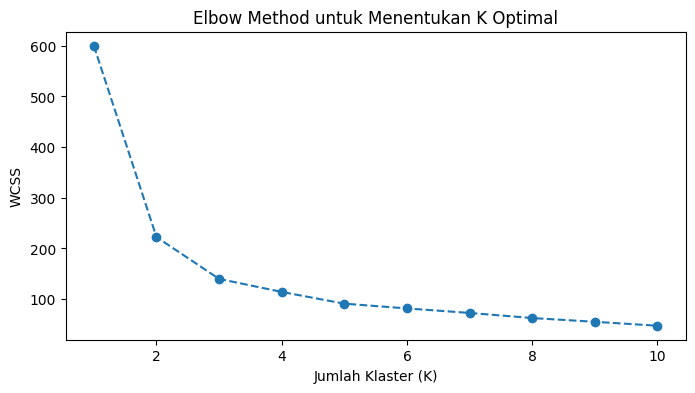

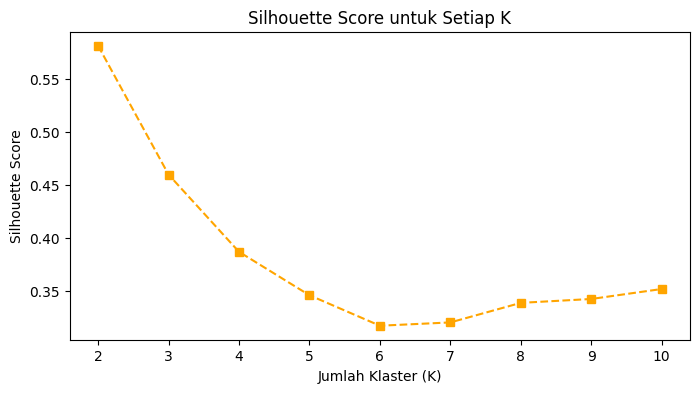

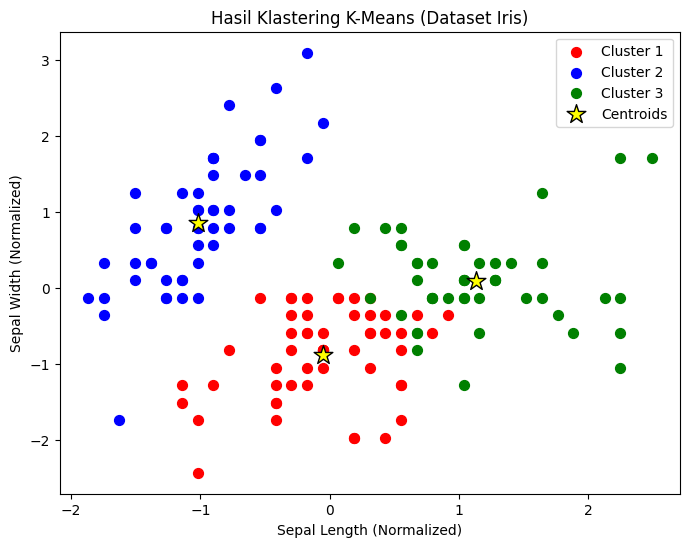


--- Proses Klastering Selesai dengan Sukses! ---


In [4]:
# 1. Import Library yang Dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("--- Library berhasil diimport! ---")

# 2. Data Understanding & Loading (Menggunakan Dataset Iris Bawaan)
df = sns.load_dataset('iris')
print("\n--- 5 Baris Pertama Dataset Iris ---")
display(df.head())

# 3. Data Preparation & Selection
# Memilih kolom numerik saja (fitur fisik bunga)
X = df.iloc[:, :-1].values

# Data Normalization (Normalisasi data agar skalanya seragam)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("\n--- Data Preparation & Normalisasi Selesai ---")

# 4. Elbow Method (Menentukan K Optimal)
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method untuk Menentukan K Optimal')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('WCSS')
plt.show()

# 5. Silhouette Score Evaluation
silhouette_scores = []
K_range = range(2, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(K_range, silhouette_scores, marker='s', color='orange', linestyle='--')
plt.title('Silhouette Score untuk Setiap K')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Silhouette Score')
plt.show()

# 6. Penerapan Algoritma K-Means (Berdasarkan Dataset Iris, K optimal = 3)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X_scaled)

# Masukkan hasil klaster ke dataframe
df['Cluster'] = y_kmeans

# 7. Visualisasi Hasil Klaster (Scatter Plot)
plt.figure(figsize=(8, 6))
colors = ['red', 'blue', 'green']
for i in range(optimal_k):
    plt.scatter(X_scaled[y_kmeans == i, 0], X_scaled[y_kmeans == i, 1], s=50, c=colors[i], label=f'Cluster {i+1}')

# Plot Centroids (Titik Pusat Klaster)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=200, c='yellow', marker='*', label='Centroids', edgecolor='black')
plt.title('Hasil Klastering K-Means (Dataset Iris)')
plt.xlabel('Sepal Length (Normalized)')
plt.ylabel('Sepal Width (Normalized)')
plt.legend()
plt.show()

print("\n--- Proses Klastering Selesai dengan Sukses! ---")